# 02 Classical Baselines

## Research-grade benchmark notebook

This notebook evaluates classical molecular generation and distribution-learning baselines for the QCBM Molecular Augmentation project.

The purpose is to establish strong non-quantum reference models before comparing against QCBM, QGAN, QVAE, and hardware-executed quantum models.

All classical baselines are evaluated under a consistent molecular-state framework:

```text
SMILES
↓
SELFIES
↓
Token-count latent vectors
↓
KMeans molecular states
↓
Classical generative model
↓
Generated states or molecules
↓
Molecular retrieval / molecular evaluation

## Classical Baselines Included

This notebook evaluates:

1. Independent Classical Born Machine  
2. Markov Chain Born Machine  
3. STONED-SELFIES molecular mutation baseline  
4. Variational Autoencoder baseline  
5. Generative Adversarial Network baseline  
6. Reinforcement Learning generator baseline  

The first two are distribution-learning baselines over discrete molecular states.

STONED, VAE, GAN, and RL are molecular generation or latent-vector generation baselines.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR)
    )

print("PROJECT_ROOT =", PROJECT_ROOT)
print("SRC_DIR =", SRC_DIR)

PROJECT_ROOT = d:\QCBM Molecular Augmentation Lite
SRC_DIR = d:\QCBM Molecular Augmentation Lite\src


In [2]:
import os
import time
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import selfies as sf

from rdkit import Chem
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")

from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity

from molaug_qcbm.encoding.kmeans import (
    selfies_to_latent,
    KMeansEncoder
)

from molaug_qcbm.baselines.classical_born import (
    ClassicalBornMachine
)

from molaug_qcbm.baselines.markov_born import (
    MarkovBornMachine
)

from molaug_qcbm.baselines.stoned import (
    STONEDGenerator
)

from molaug_qcbm.baselines.vae import (
    MolecularVAE
)

from molaug_qcbm.baselines.gan import (
    MolecularGAN
)

from molaug_qcbm.baselines.rl_generator import (
    RLMoleculeGenerator
)

from molaug_qcbm.evaluation.benchmark_metrics import (
    distribution_report
)

from molaug_qcbm.evaluation.validity import (
    validity_report
)

from molaug_qcbm.evaluation.uniqueness import (
    uniqueness_report
)

from molaug_qcbm.evaluation.novelty import (
    novelty_report
)

from molaug_qcbm.evaluation.qed import (
    qed_report
)

from molaug_qcbm.evaluation.sa_score import (
    sa_report
)

from molaug_qcbm.evaluation.syba import (
    syba_report,
    syba_score_smiles
)

from molaug_qcbm.preprocessing.descriptors import (
    descriptor_dataframe
)

print("Imports complete.")

Imports complete.


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = r"D:\QCBM Molecular Augmentation Lite"

DATA_DIR = os.path.join(
    PROJECT_ROOT,
    "data"
)

PROCESSED_DIR = os.path.join(
    DATA_DIR,
    "processed"
)

BENCHMARK_DIR = os.path.join(
    DATA_DIR,
    "benchmark_splits"
)

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "classical_baselines"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

TRAIN_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "train.parquet"
)

VALIDATION_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "validation.parquet"
)

TEST_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "test.parquet"
)

KNOWN_PARQUET = os.path.join(
    PROCESSED_DIR,
    "known_inhibitors.parquet"
)

KRAS_PARQUET = os.path.join(
    PROCESSED_DIR,
    "kras_activity.parquet"
)

N_QUBITS = 5
N_BINS = 2 ** N_QUBITS
MAX_SELFIES_TOKENS = 32

N_GENERATED = 2000
N_TRAIN_SAMPLE = 20000

VAE_EPOCHS = 10
GAN_EPOCHS = 10

print("N_BINS:", N_BINS)
print("N_GENERATED:", N_GENERATED)

N_BINS: 32
N_GENERATED: 2000


In [4]:
train_df = pd.read_parquet(
    TRAIN_PARQUET
)

validation_df = pd.read_parquet(
    VALIDATION_PARQUET
)

test_df = pd.read_parquet(
    TEST_PARQUET
)

known_df = pd.read_parquet(
    KNOWN_PARQUET
)

kras_df = pd.read_parquet(
    KRAS_PARQUET
)

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)
print("Known inhibitors:", known_df.shape)
print("KRAS:", kras_df.shape)

Train: (808408, 2)
Validation: (101051, 2)
Test: (101051, 2)
Known inhibitors: (636, 6)
KRAS: (645, 5)


## Sampling Strategy

The full STONED dataset contains approximately 1 million molecules.

For classical model development, we use a controlled training sample from the training split. This makes the notebook reproducible and computationally manageable while preserving the statistical structure of the molecular pool.

The same sampled training set is used across all baselines.

In [5]:
train_sample_df = train_df.sample(
    n=min(
        N_TRAIN_SAMPLE,
        len(train_df)
    ),
    random_state=SEED
).reset_index(
    drop=True
)

train_smiles = (
    train_sample_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

known_smiles = (
    known_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

test_smiles = (
    test_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

print("Training SMILES:", len(train_smiles))
print("Known inhibitor SMILES:", len(known_smiles))
print("Test SMILES:", len(test_smiles))

Training SMILES: 20000
Known inhibitor SMILES: 636
Test SMILES: 101051


In [6]:
def safe_selfies(
    smiles
):
    try:
        return sf.encoder(
            smiles
        )
    except Exception:
        return None


train_sample_df["selfies"] = (
    train_sample_df["smiles"]
    .apply(
        safe_selfies
    )
)

train_sample_df = (
    train_sample_df
    .dropna(
        subset=["selfies"]
    )
    .reset_index(
        drop=True
    )
)

train_smiles = (
    train_sample_df["smiles"]
    .astype(str)
    .tolist()
)

train_selfies = (
    train_sample_df["selfies"]
    .astype(str)
    .tolist()
)

print("Valid SELFIES molecules:", len(train_selfies))

Valid SELFIES molecules: 19992


## Molecular State Space

The QCBM project maps molecules into discrete molecular states.

For 5 qubits:

```text
2^5 = 32 states

In [7]:
X_latent, vocab = selfies_to_latent(
    train_selfies,
    max_tokens=MAX_SELFIES_TOKENS
)

print("Latent matrix shape:", X_latent.shape)
print("Vocabulary size:", len(vocab))
print("First 10 tokens:", vocab[:10])

Latent matrix shape: (19992, 32)
Vocabulary size: 32
First 10 tokens: ['[C]', '[=C]', '[Ring1]', '[Branch1]', '[N]', '[=N]', '[O]', '[Ring2]', '[Branch2]', '[=Branch1]']


In [8]:
kmeans_encoder = KMeansEncoder(
    n_clusters=N_BINS,
    random_state=SEED
)

state_ids = kmeans_encoder.fit_predict(
    X_latent
)

p_target = kmeans_encoder.target_distribution(
    state_ids,
    n_bins=N_BINS
)

train_sample_df["state"] = state_ids

print("Target distribution mass:", p_target.sum())
print("State counts:")
train_sample_df["state"].value_counts().sort_index().head()

Target distribution mass: 1.0
State counts:


state
0    560
1    467
2    995
3    264
4    642
Name: count, dtype: int64

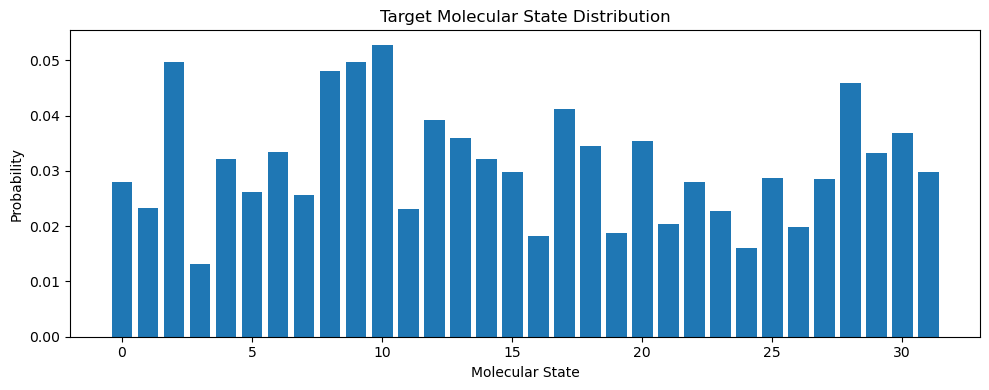

In [9]:
plt.figure(
    figsize=(10, 4)
)

plt.bar(
    np.arange(N_BINS),
    p_target
)

plt.xlabel("Molecular State")
plt.ylabel("Probability")
plt.title("Target Molecular State Distribution")
plt.tight_layout()
plt.show()

In [10]:
def normalize_distribution(
    p
):
    p = np.asarray(
        p,
        dtype=float
    )

    p = np.clip(
        p,
        1e-12,
        None
    )

    return p / p.sum()


def distribution_from_states(
    states,
    n_bins=N_BINS
):
    counts = np.bincount(
        np.asarray(
            states,
            dtype=int
        ),
        minlength=n_bins
    ).astype(float)

    if counts.sum() == 0:
        return np.ones(n_bins) / n_bins

    return counts / counts.sum()


def retrieve_molecules_from_states(
    states,
    reference_df,
    method_name,
    state_column="state",
    smiles_column="smiles",
    random_state=SEED
):
    rng = np.random.default_rng(
        random_state
    )

    records = []

    for state in states:

        pool = reference_df[
            reference_df[state_column] == int(state)
        ]

        if len(pool) == 0:
            pool = reference_df

        idx = rng.integers(
            0,
            len(pool)
        )

        row = pool.iloc[
            idx
        ]

        records.append(
            {
                "method": method_name,
                "state": int(state),
                "smiles": row[smiles_column]
            }
        )

    return pd.DataFrame(
        records
    )


def vector_to_nearest_molecules(
    generated_vectors,
    reference_vectors,
    reference_df,
    method_name,
    smiles_column="smiles"
):
    similarities = cosine_similarity(
        generated_vectors,
        reference_vectors
    )

    nearest_idx = similarities.argmax(
        axis=1
    )

    rows = []

    for i, idx in enumerate(nearest_idx):

        rows.append(
            {
                "method": method_name,
                "nearest_index": int(idx),
                "smiles": reference_df.iloc[idx][smiles_column],
                "similarity": float(similarities[i, idx])
            }
        )

    return pd.DataFrame(
        rows
    )


def molecular_quality_summary(
    method_name,
    generated_smiles,
    training_smiles
):
    validity = validity_report(
        generated_smiles
    )

    uniqueness = uniqueness_report(
        generated_smiles
    )

    novelty = novelty_report(
        generated_smiles,
        training_smiles
    )

    qed = qed_report(
        generated_smiles
    )

    sa = sa_report(
        generated_smiles
    )

    syba = syba_report(
        generated_smiles
    )

    return {
        "method": method_name,
        "generated": len(generated_smiles),
        "validity": validity["validity"],
        "uniqueness": uniqueness["uniqueness"],
        "novelty": novelty["novelty"],
        "mean_qed": qed["mean_qed"],
        "median_qed": qed["median_qed"],
        "mean_sa": sa["mean_sa"],
        "median_sa": sa["median_sa"],
        "mean_syba": syba["mean"],
        "median_syba": syba["median"]
    }

In [11]:
distribution_results = []
molecular_results = []
generated_tables = {}
runtime_results = []

# Baseline 1: Independent Classical Born Machine

The independent classical Born model assumes that each bit in the molecular state representation is statistically independent.

For a bitstring:

```text
x = (x1, x2, ..., xn)

In [12]:
start = time.perf_counter()

classical_born = ClassicalBornMachine(
    n_bits=N_QUBITS
)

classical_born.fit(
    p_target
)

p_classical_born = classical_born.probabilities()

sampled_states_classical_born = classical_born.sample_states(
    n_samples=N_GENERATED,
    random_state=SEED
)

p_classical_born_sampled = distribution_from_states(
    sampled_states_classical_born,
    n_bins=N_BINS
)

runtime = time.perf_counter() - start

runtime_results.append(
    {
        "method": "Classical_Born_Independent",
        "runtime_sec": runtime
    }
)

distribution_results.append(
    distribution_report(
        "Classical_Born_Independent",
        p_classical_born_sampled,
        p_target
    )
)

print("Runtime:", runtime)
distribution_results[-1]

Runtime: 0.06519599999592174


{'method': 'Classical_Born_Independent',
 'KL': 0.03980190195088799,
 'TV': 0.11176610644257703,
 'Fidelity': 0.9799022060340035,
 'MMD': 0.0024090781512955796,
 'Sinkhorn': 0.34378891556622615}

In [13]:
df_classical_born = retrieve_molecules_from_states(
    sampled_states_classical_born,
    train_sample_df,
    method_name="Classical_Born_Independent"
)

generated_tables[
    "Classical_Born_Independent"
] = df_classical_born

df_classical_born.head()

,method,state,smiles
0,Classical_Born_Independent,26,Cc1ccc2[nH]ncc2c1NCc1cnc(OCCC2CC2C)nc1
1,Classical_Born_Independent,16,COc1cccnc1-c1nccc(N=C(CC2CCCN2C)N=CN2CCN3CCC3C...
2,Classical_Born_Independent,2,COc1ccccc1-c1ncc2c(CCCCCO)nc(C34CCCN3CCC4)nc2c1F
3,Classical_Born_Independent,7,CCNC(=NCCc1c(C)ccc2[nH]ncc12)OCC1CCCC1
4,Classical_Born_Independent,27,CCCc1ccncc1NCc1nc(OCC2CCC2)nc(N2CCN(C)C(C)C2)c1Br


In [14]:
molecular_results.append(
    molecular_quality_summary(
        "Classical_Born_Independent",
        df_classical_born["smiles"].tolist(),
        train_smiles
    )
)

molecular_results[-1]

{'method': 'Classical_Born_Independent',
 'generated': 2000,
 'validity': 1.0,
 'uniqueness': 0.9455,
 'novelty': 0.0,
 'mean_qed': 0.6049270645535599,
 'median_qed': 0.5962295866205249,
 'mean_sa': 3.763502731187467,
 'median_sa': 3.7852324818325984,
 'mean_syba': 22.3203120069516,
 'median_syba': 18.271399633715134}

# Baseline 2: Markov Chain Born Machine

The Markov Chain Born Machine relaxes the independence assumption.

Instead of modeling all bits independently, it assumes a first-order Markov dependency:

```text
P(x) = P(x1) P(x2 | x1) P(x3 | x2) ... P(xn | x(n-1))

In [15]:
start = time.perf_counter()

markov_born = MarkovBornMachine(
    n_bits=N_QUBITS
)

markov_born.fit(
    p_target
)

p_markov_born = markov_born.probabilities()

sampled_states_markov = markov_born.sample_states(
    n_samples=N_GENERATED,
    random_state=SEED
)

p_markov_sampled = distribution_from_states(
    sampled_states_markov,
    n_bins=N_BINS
)

runtime = time.perf_counter() - start

runtime_results.append(
    {
        "method": "Classical_Born_Markov",
        "runtime_sec": runtime
    }
)

distribution_results.append(
    distribution_report(
        "Classical_Born_Markov",
        p_markov_sampled,
        p_target
    )
)

print("Runtime:", runtime)
distribution_results[-1]

Runtime: 0.21969369999715127


{'method': 'Classical_Born_Markov',
 'KL': 0.03765084567939873,
 'TV': 0.11066846738695477,
 'Fidelity': 0.9811726248255965,
 'MMD': 0.0021894160626986393,
 'Sinkhorn': 0.35226390556222564}

In [16]:
df_markov_born = retrieve_molecules_from_states(
    sampled_states_markov,
    train_sample_df,
    method_name="Classical_Born_Markov"
)

generated_tables[
    "Classical_Born_Markov"
] = df_markov_born

df_markov_born.head()

,method,state,smiles
0,Classical_Born_Markov,22,CCCCC(C)On1cnc2c1C(C)N(c1ccccc1C(C)O)C2
1,Classical_Born_Markov,28,CC1C(O)NCC1c1nc(CC23CCCN2CCC3)nc2c(F)c(Oc3cccc...
2,Classical_Born_Markov,14,CN(C)C1CN(c2nc(N3CC4CCC4C3)c3cnc(CC(=O)Oc4cccc...
3,Classical_Born_Markov,11,CCCCc1nc(COCCN)nc2c1CCN(c1cncc3cccc(C)c13)C2
4,Classical_Born_Markov,23,C=CCN1CCC1COc1ccnc(-c2cccnc2C(C)C)c1F


In [17]:
molecular_results.append(
    molecular_quality_summary(
        "Classical_Born_Markov",
        df_markov_born["smiles"].tolist(),
        train_smiles
    )
)

molecular_results[-1]

{'method': 'Classical_Born_Markov',
 'generated': 2000,
 'validity': 1.0,
 'uniqueness': 0.943,
 'novelty': 0.0,
 'mean_qed': 0.6076507461813871,
 'median_qed': 0.5944610886393265,
 'mean_sa': 3.7655955133051644,
 'median_sa': 3.7952516247738175,
 'mean_syba': 22.56789615100636,
 'median_syba': 18.520578674115484}

# Baseline 3: STONED-SELFIES

STONED generates new molecules by mutating SELFIES strings.

SELFIES is semantically robust, meaning many random mutations still decode into chemically valid molecules.

This baseline is important because it is a strong classical molecular augmentation method.

Unlike Born models, STONED is not primarily a distribution learner over molecular states. It is a molecule-space mutation generator.

In [18]:
start = time.perf_counter()

stoned_generator = STONEDGenerator(
    random_state=SEED
)

generated_stoned = stoned_generator.classical_stoned_generate(
    smiles_list=train_smiles,
    n_samples=N_GENERATED,
    depth=3
)

runtime = time.perf_counter() - start

df_stoned = pd.DataFrame(
    {
        "method": "STONED",
        "smiles": generated_stoned
    }
)

runtime_results.append(
    {
        "method": "STONED",
        "runtime_sec": runtime
    }
)

generated_tables[
    "STONED"
] = df_stoned

print("Generated:", len(generated_stoned))
print("Runtime:", runtime)

df_stoned.head()

Generated: 2000
Runtime: 2.7645472000003792


,method,smiles
0,STONED,C1CN2CCC12
1,STONED,C=[S-](C)c1ccccc1N=BCOCC1C=CN=C(OC2=CNCCC2N)C1
2,STONED,CCCCC1C=CCCO1
3,STONED,C=CCNC#CC(O)C1N(C)CCN1c1n[nH]c2c(F)c(-c3cccc(C...
4,STONED,[C-]C(C=CC=CSC)=CN1CC(N=COCCNOC=C)=CC1=N


In [19]:
stoned_selfies = [
    safe_selfies(
        smiles
    )
    for smiles in generated_stoned
]

stoned_valid_pairs = [
    (smiles, selfie)
    for smiles, selfie
    in zip(
        generated_stoned,
        stoned_selfies
    )
    if selfie is not None
]

stoned_valid_smiles = [
    item[0]
    for item in stoned_valid_pairs
]

stoned_valid_selfies = [
    item[1]
    for item in stoned_valid_pairs
]

X_stoned, _ = selfies_to_latent(
    stoned_valid_selfies,
    max_tokens=MAX_SELFIES_TOKENS
)

if X_stoned.shape[1] != X_latent.shape[1]:

    aligned = np.zeros(
        (
            X_stoned.shape[0],
            X_latent.shape[1]
        )
    )

    cols = min(
        X_stoned.shape[1],
        X_latent.shape[1]
    )

    aligned[:, :cols] = X_stoned[:, :cols]

    X_stoned = aligned

stoned_states = kmeans_encoder.predict(
    X_stoned
)

p_stoned = distribution_from_states(
    stoned_states,
    n_bins=N_BINS
)

distribution_results.append(
    distribution_report(
        "STONED",
        p_stoned,
        p_target
    )
)

distribution_results[-1]

{'method': 'STONED',
 'KL': 0.4002025820337362,
 'TV': 0.3093991736182682,
 'Fidelity': 0.8409452159727092,
 'MMD': 0.018528696753465548,
 'Sinkhorn': 0.8437327515050167}

In [20]:
molecular_results.append(
    molecular_quality_summary(
        "STONED",
        generated_stoned,
        train_smiles
    )
)

molecular_results[-1]

{'method': 'STONED',
 'generated': 2000,
 'validity': 1.0,
 'uniqueness': 0.9915,
 'novelty': 1.0,
 'mean_qed': 0.42527596430102266,
 'median_qed': 0.40804450814310117,
 'mean_sa': 5.279443136086344,
 'median_sa': 5.300096238231384,
 'mean_syba': -49.8479054228156,
 'median_syba': -48.308996241238205}

# Baseline 4: Variational Autoencoder

The VAE learns a continuous latent representation of molecular token-count vectors.

It has two components:

- Encoder: maps molecular vectors into latent Gaussian variables
- Decoder: reconstructs molecular vectors from latent variables

In this repository implementation, the VAE generates molecular vectors. To convert those vectors back into molecules, we retrieve the nearest training molecule in token-count latent space.

This makes VAE comparable to retrieval-based QCBM generation.

In [21]:
start = time.perf_counter()

vae = MolecularVAE(
    latent_dim=32,
    batch_size=256,
    epochs=VAE_EPOCHS,
    learning_rate=1e-3
)

vae.fit(
    X_latent
)

generated_vae_vectors = vae.generate(
    n_samples=N_GENERATED
)

runtime = time.perf_counter() - start

runtime_results.append(
    {
        "method": "VAE",
        "runtime_sec": runtime
    }
)

print("Runtime:", runtime)
print("Generated vector shape:", generated_vae_vectors.shape)
vae.summary()

Runtime: 9.020354300009785
Generated vector shape: (2000, 32)


{'latent_dim': 32,
 'epochs': 10,
 'batch_size': 256,
 'device': 'cpu',
 'trained': True}

In [22]:
start = time.perf_counter()

vae = MolecularVAE(
    latent_dim=32,
    batch_size=256,
    epochs=VAE_EPOCHS,
    learning_rate=1e-3
)

vae.fit(
    X_latent
)

generated_vae_vectors = vae.generate(
    n_samples=N_GENERATED
)

runtime = time.perf_counter() - start

runtime_results.append(
    {
        "method": "VAE",
        "runtime_sec": runtime
    }
)

print("Runtime:", runtime)
print("Generated vector shape:", generated_vae_vectors.shape)
vae.summary()

Runtime: 5.78656389999378
Generated vector shape: (2000, 32)


{'latent_dim': 32,
 'epochs': 10,
 'batch_size': 256,
 'device': 'cpu',
 'trained': True}

In [23]:
df_vae = vector_to_nearest_molecules(
    generated_vectors=generated_vae_vectors,
    reference_vectors=X_latent,
    reference_df=train_sample_df,
    method_name="VAE"
)

generated_tables[
    "VAE"
] = df_vae

df_vae.head()

,method,nearest_index,smiles,similarity
0,VAE,11213,CN(CC1CCC1N)c1nc(OCC23CCCN2CCC3)nc2c(F)c(-c3cc...,0.997684
1,VAE,7623,Cc1nc(OCC23CCCN2CCC3)nc(NCC2CCN2)c1CCc1cncc2cc...,0.997551
2,VAE,11213,CN(CC1CCC1N)c1nc(OCC23CCCN2CCC3)nc2c(F)c(-c3cc...,0.997711
3,VAE,11213,CN(CC1CCC1N)c1nc(OCC23CCCN2CCC3)nc2c(F)c(-c3cc...,0.998261
4,VAE,8104,CC(=CN)CCc1nc(OCC23CCCN2CCC3)nc2c(F)c(-c3cccc(...,0.997980


In [24]:
vae_nearest_indices = df_vae[
    "nearest_index"
].values

vae_states = train_sample_df.iloc[
    vae_nearest_indices
]["state"].values

p_vae = distribution_from_states(
    vae_states,
    n_bins=N_BINS
)

distribution_results.append(
    distribution_report(
        "VAE",
        p_vae,
        p_target
    )
)

distribution_results[-1]

{'method': 'VAE',
 'KL': 17.82722748091654,
 'TV': 0.8519501800466397,
 'Fidelity': 0.1094134093051553,
 'MMD': 0.6237991704434291,
 'Sinkhorn': 7.2512152859256584}

In [25]:
molecular_results.append(
    molecular_quality_summary(
        "VAE",
        df_vae["smiles"].tolist(),
        train_smiles
    )
)

molecular_results[-1]

{'method': 'VAE',
 'generated': 2000,
 'validity': 1.0,
 'uniqueness': 0.006,
 'novelty': 0.0,
 'mean_qed': 0.5204992542746031,
 'median_qed': 0.514839598060731,
 'mean_sa': 4.140919182594107,
 'median_sa': 4.211921450317746,
 'mean_syba': 8.406126581507646,
 'median_syba': 7.206118029105911}

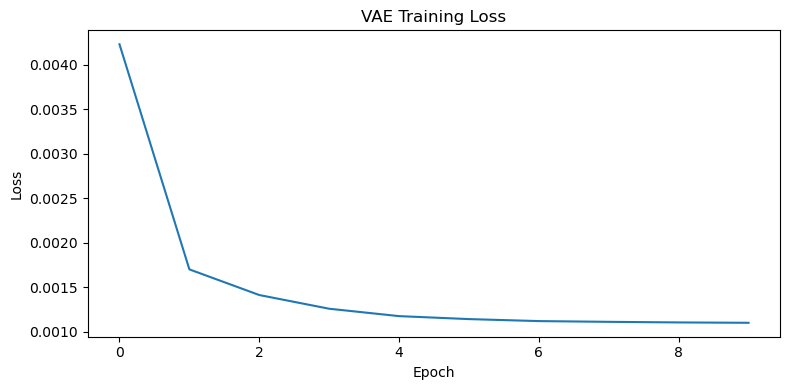

In [26]:
plt.figure(
    figsize=(8, 4)
)

plt.plot(
    vae.loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.tight_layout()
plt.show()

# Baseline 5: Generative Adversarial Network

The GAN learns to generate molecular token-count vectors through adversarial training.

It has two networks:

- Generator: produces synthetic molecular vectors
- Discriminator: distinguishes real molecular vectors from generated ones

As with the VAE, generated vectors are mapped back to molecules through nearest-neighbor retrieval in the latent token-count space.

In [27]:
start = time.perf_counter()

gan = MolecularGAN(
    latent_dim=32,
    batch_size=256,
    epochs=GAN_EPOCHS,
    learning_rate=2e-4
)

gan.fit(
    X_latent
)

generated_gan_vectors = gan.generate(
    n_samples=N_GENERATED
)

runtime = time.perf_counter() - start

runtime_results.append(
    {
        "method": "GAN",
        "runtime_sec": runtime
    }
)

print("Runtime:", runtime)
print("Generated vector shape:", generated_gan_vectors.shape)
gan.summary()

Runtime: 7.086075400002301
Generated vector shape: (2000, 32)


{'model': 'GAN',
 'latent_dim': 32,
 'epochs': 10,
 'batch_size': 256,
 'device': 'cpu',
 'trained': True}

In [28]:
df_gan = vector_to_nearest_molecules(
    generated_vectors=generated_gan_vectors,
    reference_vectors=X_latent,
    reference_df=train_sample_df,
    method_name="GAN"
)

generated_tables[
    "GAN"
] = df_gan

df_gan.head()

,method,nearest_index,smiles,similarity
0,GAN,1622,CCC1CN(c2nc(OCCC#N)nc(C)c2Cc2cncc3cccc(C)c23)CCN1,0.987574
1,GAN,2040,C=CNN1CCCC1COc1nc(NCC(C)N)c2cnc(-c3ccccc3F)c(F...,0.988872
2,GAN,7507,C=C(C=CC=Cc1ncc2c(NC3CCN(C)C3)nc(OC3CCCN(CC)C3...,0.990118
3,GAN,10004,C=CCC(C=C)(COc1nc(N2CCC(N)C2)c2cnc(-c3ccccc3Cl...,0.984428
4,GAN,2040,C=CNN1CCCC1COc1nc(NCC(C)N)c2cnc(-c3ccccc3F)c(F...,0.990615


In [29]:
gan_nearest_indices = df_gan[
    "nearest_index"
].values

gan_states = train_sample_df.iloc[
    gan_nearest_indices
]["state"].values

p_gan = distribution_from_states(
    gan_states,
    n_bins=N_BINS
)

distribution_results.append(
    distribution_report(
        "GAN",
        p_gan,
        p_target
    )
)

distribution_results[-1]

{'method': 'GAN',
 'KL': 12.07135192807309,
 'TV': 0.7756142456835743,
 'Fidelity': 0.21125902057007517,
 'MMD': 0.33535087447561385,
 'Sinkhorn': 5.620663265213136}

In [30]:
molecular_results.append(
    molecular_quality_summary(
        "GAN",
        df_gan["smiles"].tolist(),
        train_smiles
    )
)

molecular_results[-1]

{'method': 'GAN',
 'generated': 2000,
 'validity': 1.0,
 'uniqueness': 0.067,
 'novelty': 0.0,
 'mean_qed': 0.5291191330668653,
 'median_qed': 0.45914455663949544,
 'mean_sa': 4.082539903977425,
 'median_sa': 4.107062782702268,
 'mean_syba': 12.972421876305631,
 'median_syba': 11.469191746452843}

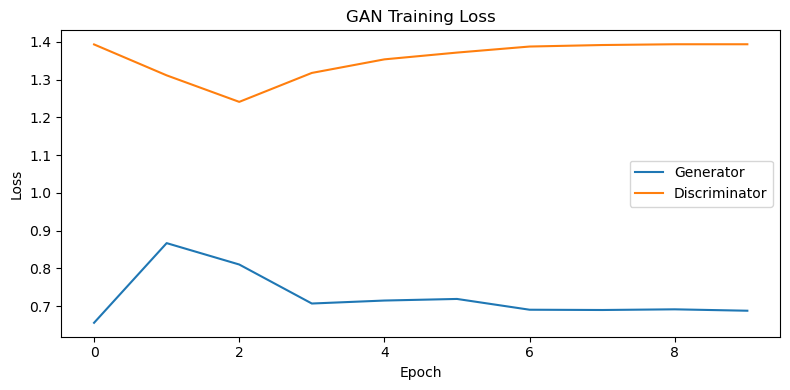

In [31]:
history = gan.training_history()

plt.figure(
    figsize=(8, 4)
)

plt.plot(
    history["generator_loss"],
    label="Generator"
)

plt.plot(
    history["discriminator_loss"],
    label="Discriminator"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.tight_layout()
plt.show()

# Baseline 6: Reinforcement Learning Generator

The RL baseline scores molecules using a reward function.

The reward combines:

```text
SYBA + QED + Novelty

In [32]:
start = time.perf_counter()

print("Initializing...")
rl_generator = RLMoleculeGenerator(
    reward_weight_syba=1.0,
    reward_weight_qed=1.0,
    reward_weight_novelty=1.0,
    random_state=SEED
)

print("Starting fit...")
t0 = time.perf_counter()

rl_generator.fit(train_smiles)

print("Fit finished in", time.perf_counter() - t0)

print("Generating...")
t1 = time.perf_counter()

generated_rl = rl_generator.generate(
    n_samples=N_GENERATED,
    exploration_rate=0.1
)

print("Generation finished in", time.perf_counter() - t1)

Initializing...
Starting fit...
Processed 5,000 molecules...
Processed 10,000 molecules...
Processed 15,000 molecules...
Fit finished in 117.16154069999175
Generating...
Generation finished in 0.002793000006931834


In [33]:
start = time.perf_counter()

rl_generator = RLMoleculeGenerator(
    reward_weight_syba=1.0,
    reward_weight_qed=1.0,
    reward_weight_novelty=1.0,
    random_state=SEED
)

rl_generator.fit(
    train_smiles
)

generated_rl = rl_generator.generate(
    n_samples=N_GENERATED,
    exploration_rate=0.1
)

runtime = time.perf_counter() - start

runtime_results.append(
    {
        "method": "RL_Generator",
        "runtime_sec": runtime
    }
)

df_rl = pd.DataFrame(
    {
        "method": "RL_Generator",
        "smiles": generated_rl
    }
)

generated_tables[
    "RL_Generator"
] = df_rl

print("Runtime:", runtime)
print("Generated:", len(generated_rl))

rl_generator.summary()

Processed 5,000 molecules...
Processed 10,000 molecules...
Processed 15,000 molecules...
Runtime: 120.31499199999962
Generated: 2000


{'method': 'RL Generator',
 'fitted': True,
 'training_molecules': 19992,
 'reward_weight_syba': 1.0,
 'reward_weight_qed': 1.0,
 'reward_weight_novelty': 1.0}

In [34]:
rl_selfies = [
    safe_selfies(
        smiles
    )
    for smiles in generated_rl
]

rl_valid_pairs = [
    (smiles, selfie)
    for smiles, selfie
    in zip(
        generated_rl,
        rl_selfies
    )
    if selfie is not None
]

rl_valid_selfies = [
    item[1]
    for item in rl_valid_pairs
]

X_rl, _ = selfies_to_latent(
    rl_valid_selfies,
    max_tokens=MAX_SELFIES_TOKENS
)

if X_rl.shape[1] != X_latent.shape[1]:

    aligned = np.zeros(
        (
            X_rl.shape[0],
            X_latent.shape[1]
        )
    )

    cols = min(
        X_rl.shape[1],
        X_latent.shape[1]
    )

    aligned[:, :cols] = X_rl[:, :cols]

    X_rl = aligned

rl_states = kmeans_encoder.predict(
    X_rl
)

p_rl = distribution_from_states(
    rl_states,
    n_bins=N_BINS
)

distribution_results.append(
    distribution_report(
        "RL_Generator",
        p_rl,
        p_target
    )
)

distribution_results[-1]

{'method': 'RL_Generator',
 'KL': 0.07199924778459336,
 'TV': 0.1485686274509804,
 'Fidelity': 0.965716869022225,
 'MMD': 0.003030616457558923,
 'Sinkhorn': 0.2837220888355344}

In [35]:
molecular_results.append(
    molecular_quality_summary(
        "RL_Generator",
        generated_rl,
        train_smiles
    )
)

molecular_results[-1]

{'method': 'RL_Generator',
 'generated': 2000,
 'validity': 1.0,
 'uniqueness': 0.675,
 'novelty': 0.0,
 'mean_qed': 0.6134701761225594,
 'median_qed': 0.6041794287927432,
 'mean_sa': 3.386766224745117,
 'median_sa': 3.421559436653591,
 'mean_syba': 56.05092802237624,
 'median_syba': 55.54740731193549}

In [36]:
rl_top_df = rl_generator.top_molecules(
    top_k=20
)

rl_top_df

,SMILES,SYBA,QED,Reward
0,CN(CC1CCC1)c1cc(CNc2cccc3c2CCCC3)nc(OCC2CCCN2C)n1,108.859990,0.600076,109.460066
1,CCCOc1ccc(CNc2cc(F)ccc2C(F)(F)F)cn1,106.066350,0.784502,106.850852
2,Cc1nc(OCC2CCCN2C)nc(N(C)C)c1CC(=O)NCc1ccccc1,103.530416,0.736309,104.266726
3,CCN1CCN(c2nc(OCC3CCCN3C)nc(C)c2CCNc2nccc3ccccc...,102.172105,0.489026,102.661131
4,CCCCn1ccnc1COCCN(C)c1ccccc1Cl,98.964379,0.654162,99.618541
5,Cc1cc(Nc2cccc3[nH]ncc23)nc(COCC2CC2)n1,98.106657,0.730189,98.836846
6,CCOc1nc(NCCc2ccccc2F)c2cnccc2n1,96.630510,0.757083,97.387593
7,NC(c1nccc(CCc2cccc(C(F)(F)F)c2)n1)c1ccccc1F,95.886802,0.669783,96.556585
8,CCN(Cc1cc(N(C)C2CCC2)nc(OCC2CCCN2C)n1)c1cncc2c...,95.401522,0.465497,95.867019
9,CC1CCC1COc1ccc(CNc2cccc3[nH]ncc23)cn1,94.700482,0.719975,95.420457


# Unified Benchmark

All baseline models are now evaluated using the same two categories of metrics.

## Distribution-learning metrics

These compare generated molecular-state distributions against the reference KMeans state distribution:

- KL Divergence
- Total Variation Distance
- Fidelity
- MMD
- Sinkhorn / Wasserstein

## Molecular-quality metrics

These evaluate the generated molecules themselves:

- Validity
- Uniqueness
- Novelty
- QED
- SA Score
- SYBA

In [37]:
distribution_df = pd.DataFrame(
    distribution_results
)

distribution_df

,method,KL,TV,Fidelity,MMD,Sinkhorn
0,Classical_Born_Independent,0.039802,0.111766,0.979902,0.002409,0.343789
1,Classical_Born_Markov,0.037651,0.110668,0.981173,0.002189,0.352264
2,STONED,0.400203,0.309399,0.840945,0.018529,0.843733
3,VAE,17.827227,0.851950,0.109413,0.623799,7.251215
4,GAN,12.071352,0.775614,0.211259,0.335351,5.620663
5,RL_Generator,0.071999,0.148569,0.965717,0.003031,0.283722


In [38]:
molecular_df = pd.DataFrame(
    molecular_results
)

molecular_df

,method,generated,validity,uniqueness,novelty,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba
0,Classical_Born_Independent,2000,1.0,0.9455,0.0,0.604927,0.596230,3.763503,3.785232,22.320312,18.271400
1,Classical_Born_Markov,2000,1.0,0.9430,0.0,0.607651,0.594461,3.765596,3.795252,22.567896,18.520579
2,STONED,2000,1.0,0.9915,1.0,0.425276,0.408045,5.279443,5.300096,-49.847905,-48.308996
3,VAE,2000,1.0,0.0060,0.0,0.520499,0.514840,4.140919,4.211921,8.406127,7.206118
4,GAN,2000,1.0,0.0670,0.0,0.529119,0.459145,4.082540,4.107063,12.972422,11.469192
5,RL_Generator,2000,1.0,0.6750,0.0,0.613470,0.604179,3.386766,3.421559,56.050928,55.547407


In [39]:
runtime_df = pd.DataFrame(
    runtime_results
)

runtime_df

,method,runtime_sec
0,Classical_Born_Independent,0.065196
1,Classical_Born_Markov,0.219694
2,STONED,2.764547
3,VAE,9.020354
4,VAE,5.786564
5,GAN,7.086075
6,RL_Generator,120.314992


In [40]:
benchmark_df = (
    distribution_df
    .merge(
        molecular_df,
        on="method",
        how="left"
    )
    .merge(
        runtime_df,
        on="method",
        how="left"
    )
)

benchmark_df = benchmark_df.sort_values(
    by=[
        "KL",
        "TV"
    ],
    ascending=True
).reset_index(
    drop=True
)

benchmark_df

,method,KL,TV,Fidelity,MMD,Sinkhorn,generated,validity,uniqueness,novelty,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba,runtime_sec
0,Classical_Born_Markov,0.037651,0.110668,0.981173,0.002189,0.352264,2000,1.0,0.9430,0.0,0.607651,0.594461,3.765596,3.795252,22.567896,18.520579,0.219694
1,Classical_Born_Independent,0.039802,0.111766,0.979902,0.002409,0.343789,2000,1.0,0.9455,0.0,0.604927,0.596230,3.763503,3.785232,22.320312,18.271400,0.065196
2,RL_Generator,0.071999,0.148569,0.965717,0.003031,0.283722,2000,1.0,0.6750,0.0,0.613470,0.604179,3.386766,3.421559,56.050928,55.547407,120.314992
3,STONED,0.400203,0.309399,0.840945,0.018529,0.843733,2000,1.0,0.9915,1.0,0.425276,0.408045,5.279443,5.300096,-49.847905,-48.308996,2.764547
4,GAN,12.071352,0.775614,0.211259,0.335351,5.620663,2000,1.0,0.0670,0.0,0.529119,0.459145,4.082540,4.107063,12.972422,11.469192,7.086075
5,VAE,17.827227,0.851950,0.109413,0.623799,7.251215,2000,1.0,0.0060,0.0,0.520499,0.514840,4.140919,4.211921,8.406127,7.206118,9.020354
6,VAE,17.827227,0.851950,0.109413,0.623799,7.251215,2000,1.0,0.0060,0.0,0.520499,0.514840,4.140919,4.211921,8.406127,7.206118,5.786564


In [41]:
distribution_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classical_distribution_metrics.csv"
    ),
    index=False
)

molecular_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classical_molecular_quality.csv"
    ),
    index=False
)

runtime_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classical_runtime.csv"
    ),
    index=False
)

benchmark_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classical_baseline_benchmark.csv"
    ),
    index=False
)

print("Saved results to:", RESULTS_DIR)

Saved results to: D:\QCBM Molecular Augmentation Lite\results\classical_baselines


In [42]:
for method_name, df_gen in generated_tables.items():

    output_path = os.path.join(
        RESULTS_DIR,
        f"generated_{method_name}.csv"
    )

    df_gen.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

Saved: D:\QCBM Molecular Augmentation Lite\results\classical_baselines\generated_Classical_Born_Independent.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\classical_baselines\generated_Classical_Born_Markov.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\classical_baselines\generated_STONED.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\classical_baselines\generated_VAE.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\classical_baselines\generated_GAN.csv
Saved: D:\QCBM Molecular Augmentation Lite\results\classical_baselines\generated_RL_Generator.csv


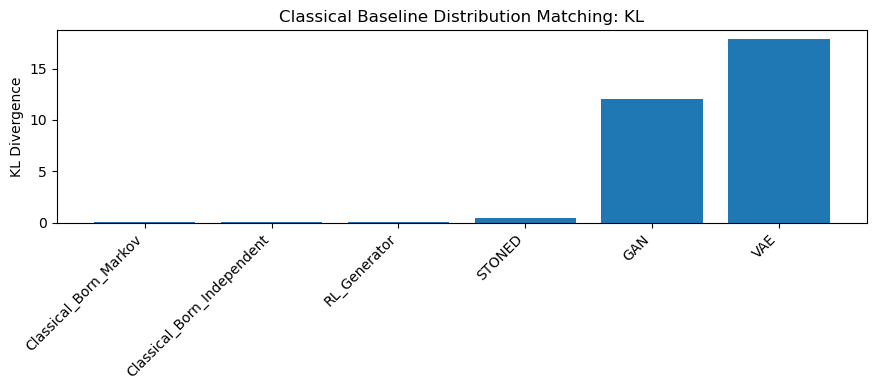

In [43]:
plt.figure(
    figsize=(9, 4)
)

plt.bar(
    benchmark_df["method"],
    benchmark_df["KL"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("KL Divergence")
plt.title("Classical Baseline Distribution Matching: KL")
plt.tight_layout()
plt.show()

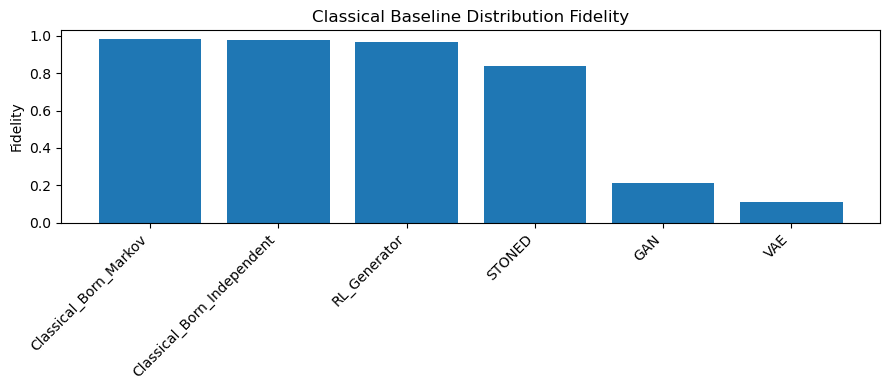

In [44]:
plt.figure(
    figsize=(9, 4)
)

plt.bar(
    benchmark_df["method"],
    benchmark_df["Fidelity"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("Fidelity")
plt.title("Classical Baseline Distribution Fidelity")
plt.tight_layout()
plt.show()

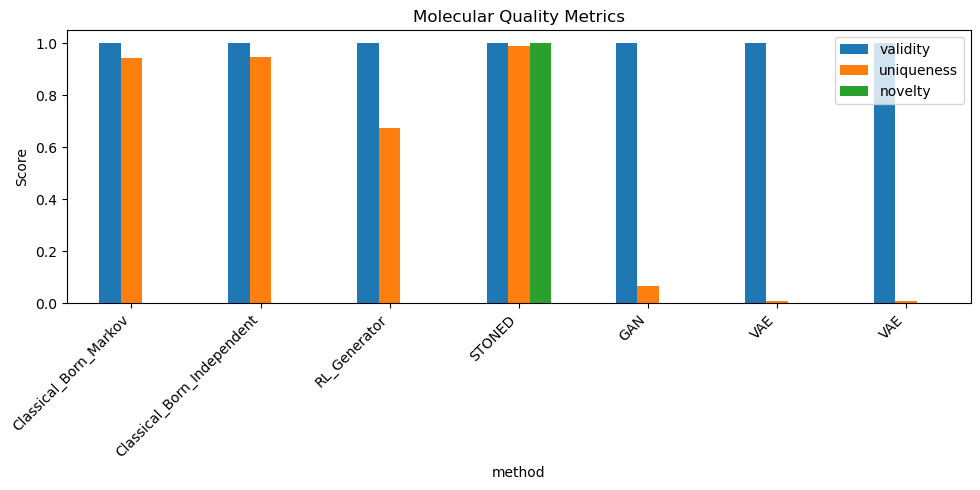

In [45]:
quality_plot_df = benchmark_df[
    [
        "method",
        "validity",
        "uniqueness",
        "novelty"
    ]
].dropna()

quality_plot_df.set_index(
    "method"
).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Score")
plt.title("Molecular Quality Metrics")
plt.xticks(
    rotation=45,
    ha="right"
)
plt.tight_layout()
plt.show()

In [46]:
druglike_plot_df = benchmark_df[
    [
        "method",
        "mean_qed",
        "mean_sa",
        "mean_syba"
    ]
].dropna()

druglike_plot_df

,method,mean_qed,mean_sa,mean_syba
0,Classical_Born_Markov,0.607651,3.765596,22.567896
1,Classical_Born_Independent,0.604927,3.763503,22.320312
2,RL_Generator,0.613470,3.386766,56.050928
3,STONED,0.425276,5.279443,-49.847905
4,GAN,0.529119,4.082540,12.972422
5,VAE,0.520499,4.140919,8.406127
6,VAE,0.520499,4.140919,8.406127


In [47]:
descriptor_comparison_rows = []

for method_name, df_gen in generated_tables.items():

    smiles = (
        df_gen["smiles"]
        .dropna()
        .astype(str)
        .tolist()
    )

    sample_smiles = smiles[
        :min(
            1000,
            len(smiles)
        )
    ]

    desc = descriptor_dataframe(
        sample_smiles
    )

    descriptor_comparison_rows.append(
        {
            "method": method_name,
            "MolWt": desc["MolWt"].mean(),
            "LogP": desc["LogP"].mean(),
            "TPSA": desc["TPSA"].mean(),
            "HBD": desc["HBD"].mean(),
            "HBA": desc["HBA"].mean(),
            "RingCount": desc["RingCount"].mean(),
            "HeavyAtoms": desc["HeavyAtoms"].mean()
        }
    )

descriptor_comparison_df = pd.DataFrame(
    descriptor_comparison_rows
)

descriptor_comparison_df

,method,MolWt,LogP,TPSA,HBD,HBA,RingCount,HeavyAtoms
0,Classical_Born_Independent,415.723566,3.584608,67.81749,1.386,6.025,4.283,29.930
1,Classical_Born_Markov,415.524783,3.544138,68.63806,1.404,6.093,4.349,29.953
2,STONED,371.654493,2.796982,62.97838,1.570,5.220,2.830,25.888
3,VAE,489.158871,3.802691,95.54766,1.947,7.844,5.897,35.747
4,GAN,444.831304,3.806191,78.55738,1.715,6.708,4.230,31.990
5,RL_Generator,413.409418,3.715531,64.81797,1.132,5.957,4.111,29.860


In [48]:
descriptor_comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classical_descriptor_comparison.csv"
    ),
    index=False
)

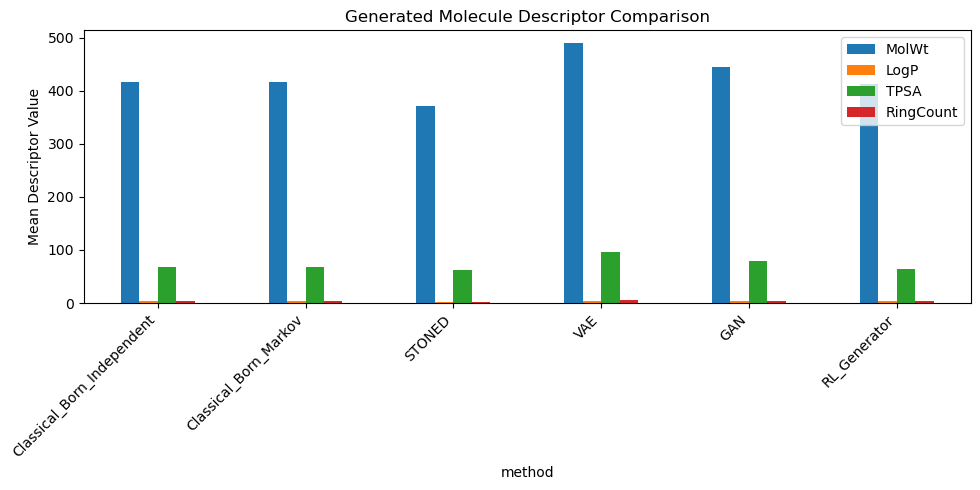

In [49]:
descriptor_comparison_df.set_index(
    "method"
)[
    [
        "MolWt",
        "LogP",
        "TPSA",
        "RingCount"
    ]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Generated Molecule Descriptor Comparison")
plt.ylabel("Mean Descriptor Value")
plt.xticks(
    rotation=45,
    ha="right"
)
plt.tight_layout()
plt.show()

# Why This Notebook Matters for the QCBM Study

This notebook establishes the classical baseline frontier.

The later QCBM notebooks should be compared against these baselines on two axes:

## 1. Distribution Learning

Does QCBM better reproduce the empirical molecular-state distribution?

Key metrics:

- KL Divergence
- Total Variation
- Fidelity
- MMD
- Sinkhorn

## 2. Molecular Quality

Does QCBM retrieve or generate molecules with competitive chemical quality?

Key metrics:

- Validity
- Uniqueness
- Novelty
- QED
- SA Score
- SYBA

A strong QCBM result should not merely generate valid molecules. It should show better distribution matching than classical Born and Markov Born models while preserving competitive molecular quality.

In [50]:
print("=" * 80)
print("CLASSICAL BASELINE NOTEBOOK COMPLETE")
print("=" * 80)

print("\nModels evaluated:")
for method in benchmark_df["method"].tolist():
    print("-", method)

print("\nBest distribution learner by KL:")
display(
    benchmark_df.sort_values(
        "KL",
        ascending=True
    ).head(1)
)

print("\nBest molecular quality by QED:")
display(
    benchmark_df.sort_values(
        "mean_qed",
        ascending=False
    ).head(1)
)

print("\nMost novel baseline:")
display(
    benchmark_df.sort_values(
        "novelty",
        ascending=False
    ).head(1)
)

CLASSICAL BASELINE NOTEBOOK COMPLETE

Models evaluated:
- Classical_Born_Markov
- Classical_Born_Independent
- RL_Generator
- STONED
- GAN
- VAE
- VAE

Best distribution learner by KL:


,method,KL,TV,Fidelity,MMD,Sinkhorn,generated,validity,uniqueness,novelty,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba,runtime_sec
0,Classical_Born_Markov,0.037651,0.110668,0.981173,0.002189,0.352264,2000,1.0,0.943,0.0,0.607651,0.594461,3.765596,3.795252,22.567896,18.520579,0.219694



Best molecular quality by QED:


,method,KL,TV,Fidelity,MMD,Sinkhorn,generated,validity,uniqueness,novelty,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba,runtime_sec
2,RL_Generator,0.071999,0.148569,0.965717,0.003031,0.283722,2000,1.0,0.675,0.0,0.61347,0.604179,3.386766,3.421559,56.050928,55.547407,120.314992



Most novel baseline:


,method,KL,TV,Fidelity,MMD,Sinkhorn,generated,validity,uniqueness,novelty,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba,runtime_sec
3,STONED,0.400203,0.309399,0.840945,0.018529,0.843733,2000,1.0,0.9915,1.0,0.425276,0.408045,5.279443,5.300096,-49.847905,-48.308996,2.764547


# Notebook Outputs

This notebook produced:

```text
results/classical_baselines/

├── classical_distribution_metrics.csv
├── classical_molecular_quality.csv
├── classical_runtime.csv
├── classical_baseline_benchmark.csv
├── classical_descriptor_comparison.csv
├── generated_Classical_Born_Independent.csv
├── generated_Classical_Born_Markov.csv
├── generated_STONED.csv
├── generated_VAE.csv
├── generated_GAN.csv
├── generated_RL_Generator.csv